# ECS 174 Homework 2

Sol Abrian

Three experiments, all trained for 5 epochs from the PyTorch DCGAN faces tutorial. Images are 64x64, scaled to the range -1 to 1. Adam uses learning rate 0.0002 and beta1 0.5, batch size 128, and binary cross entropy.

CelebA has 202,599 images. On this CPU a full pass takes a little over 3 hours, so each experiment uses the first 12,800 images (100 batches). The networks, the loss, and the number of epochs match the tutorial. Each experiment shows the generator on the same fixed noise batch after every epoch.

Training code for all three experiments. `mode` selects the run.

In [1]:
"""ECS 174 HW2 training for the CelebA DCGAN.

tutorial: the tutorial generator and discriminator, one update each per batch.
d5: the discriminator every batch, the generator every fifth batch.
simple: the two-convolution discriminator from the assignment.
"""

import argparse
import json
import os
import random
import time

os.environ.setdefault("OMP_NUM_THREADS", "16")
os.environ.setdefault("MKL_NUM_THREADS", "16")

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils

torch.set_num_threads(16)

ROOT = os.path.dirname(os.path.abspath(__file__))
DATAROOT = os.path.join(ROOT, "data", "celeba")
RUNS = os.path.join(ROOT, "runs")

batch_size = 128
image_size = 64
nc = 3
nz = 100
ngf = 64
ndf = 64
num_epochs = 5
lr = 0.0002
beta1 = 0.5
ngpu = 0
manual_seed = 999


class Generator(nn.Module):
    def __init__(self, ngpu):
        super().__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, input):
        return self.main(input)


class Discriminator(nn.Module):
    def __init__(self, ngpu):
        super().__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, input):
        return self.main(input)


class SimpleDiscriminator(nn.Module):
    """Two convolutions, then a 1x1 average pool and a sigmoid."""

    def __init__(self, ngpu):
        super().__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 1, kernel_size=4, stride=1, bias=False),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Sigmoid(),
        )

    def forward(self, input):
        return self.main(input)


def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


def save_grid(images, path):
    grid = vutils.make_grid(images, padding=2, normalize=True)
    plt.figure(figsize=(8, 8))
    plt.axis("off")
    plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    plt.close()


def plot_losses(d_losses, g_losses, g_steps, path):
    plt.figure(figsize=(10, 5))
    plt.title("Generator and Discriminator Loss During Training")
    plt.plot(g_steps, g_losses, label="G")
    plt.plot(d_losses, label="D")
    plt.xlabel("iterations")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    plt.close()


def train_one(mode, epochs, max_images, workers):
    out = os.path.join(RUNS, mode)
    os.makedirs(out, exist_ok=True)
    log_path = os.path.join(out, "log.txt")
    ckpt_path = os.path.join(out, "checkpoint.pt")

    random.seed(manual_seed)
    torch.manual_seed(manual_seed)

    dataset = dset.ImageFolder(
        root=DATAROOT,
        transform=transforms.Compose(
            [
                transforms.Resize(image_size),
                transforms.CenterCrop(image_size),
                transforms.ToTensor(),
                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
            ]
        ),
    )
    if max_images and max_images < len(dataset):
        dataset = torch.utils.data.Subset(dataset, list(range(max_images)))
    dataloader = torch.utils.data.DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=workers,
        persistent_workers=workers > 0,
    )
    device = torch.device("cpu")

    d_repeat = 5 if mode == "d5" else 1
    netG = Generator(ngpu).to(device)
    if mode == "simple":
        netD = SimpleDiscriminator(ngpu).to(device)
    else:
        netD = Discriminator(ngpu).to(device)
    netG.apply(weights_init)
    netD.apply(weights_init)

    with open(os.path.join(out, "models.txt"), "w", encoding="utf-8") as f:
        f.write(str(netG) + "\n\n" + str(netD) + "\n")

    criterion = nn.BCELoss()
    fixed_noise = torch.randn(64, nz, 1, 1, device=device)
    real_label = 1.0
    fake_label = 0.0
    optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
    optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

    G_losses = []
    D_losses = []
    g_steps = []
    start_epoch = 0
    iters = 0
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        if ckpt.get("finished"):
            plot_losses(
                ckpt["D_losses"],
                ckpt["G_losses"],
                ckpt["g_steps"],
                os.path.join(out, "loss_curve.png"),
            )
            print(f"{mode} already finished")
            return
        netG.load_state_dict(ckpt["netG"])
        netD.load_state_dict(ckpt["netD"])
        optimizerG.load_state_dict(ckpt["optG"])
        optimizerD.load_state_dict(ckpt["optD"])
        fixed_noise = ckpt["fixed_noise"]
        G_losses = ckpt["G_losses"]
        D_losses = ckpt["D_losses"]
        g_steps = ckpt["g_steps"]
        start_epoch = ckpt["epoch"] + 1
        iters = ckpt["iters"]
        print(f"Resuming {mode} at epoch {start_epoch}")

    def log(msg):
        print(msg, flush=True)
        with open(log_path, "a", encoding="utf-8") as f:
            f.write(msg + "\n")

    if start_epoch == 0 and iters == 0:
        real_batch = next(iter(dataloader))
        save_grid(real_batch[0][:64], os.path.join(out, "training_images.png"))
        note = f"dataset images: {len(dataset)}"
        if max_images and max_images < 202599:
            note += f" (first {len(dataset)} of 202599 CelebA images)"
        log(note)
        log(f"dataloader workers: {workers}")
        log(f"batches per epoch: {len(dataloader)}")
        log("Starting Training Loop...")

    for epoch in range(start_epoch, epochs):
        epoch_t = time.perf_counter()
        last_errG = float("nan")
        last_dg2 = float("nan")
        for i, data in enumerate(dataloader):
            netD.zero_grad()
            real_cpu = data[0].to(device)
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
            output = netD(real_cpu).view(-1)
            errD_real = criterion(output, label)
            errD_real.backward()
            D_x = output.mean().item()

            noise = torch.randn(b_size, nz, 1, 1, device=device)
            fake = netG(noise)
            label.fill_(fake_label)
            output = netD(fake.detach()).view(-1)
            errD_fake = criterion(output, label)
            errD_fake.backward()
            D_G_z1 = output.mean().item()
            errD = errD_real + errD_fake
            optimizerD.step()

            if iters % d_repeat == 0:
                netG.zero_grad()
                label.fill_(real_label)
                output = netD(fake).view(-1)
                errG = criterion(output, label)
                errG.backward()
                last_dg2 = output.mean().item()
                last_errG = errG.item()
                optimizerG.step()
                G_losses.append(last_errG)
                g_steps.append(iters)

            D_losses.append(errD.item())

            if i % 50 == 0:
                log(
                    "[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f"
                    % (
                        epoch,
                        epochs,
                        i,
                        len(dataloader),
                        errD.item(),
                        last_errG,
                        D_x,
                        D_G_z1,
                        last_dg2,
                    )
                )

            if iters % 500 == 0 or (
                epoch == epochs - 1 and i == len(dataloader) - 1
            ):
                with torch.no_grad():
                    snap = netG(fixed_noise).detach().cpu()
                save_grid(snap, os.path.join(out, f"snap_{iters:06d}.png"))

            iters += 1

        with torch.no_grad():
            epoch_fake = netG(fixed_noise).detach().cpu()
        save_grid(epoch_fake, os.path.join(out, f"epoch_{epoch + 1}.png"))
        elapsed = time.perf_counter() - epoch_t
        log(f"epoch {epoch + 1} done in {elapsed:.1f}s")
        torch.save(
            {
                "epoch": epoch,
                "iters": iters,
                "netG": netG.state_dict(),
                "netD": netD.state_dict(),
                "optG": optimizerG.state_dict(),
                "optD": optimizerD.state_dict(),
                "fixed_noise": fixed_noise,
                "G_losses": G_losses,
                "D_losses": D_losses,
                "g_steps": g_steps,
                "finished": epoch + 1 >= epochs,
            },
            ckpt_path,
        )

    plot_losses(D_losses, G_losses, g_steps, os.path.join(out, "loss_curve.png"))
    with torch.no_grad():
        final_fake = netG(fixed_noise).detach().cpu()
    real_batch = next(iter(dataloader))
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.axis("off")
    ax.set_title("Real Images")
    ax.imshow(
        np.transpose(
            vutils.make_grid(real_batch[0][:64], padding=5, normalize=True).numpy(),
            (1, 2, 0),
        )
    )
    ax = fig.add_subplot(1, 2, 2)
    ax.axis("off")
    ax.set_title("Fake Images")
    ax.imshow(
        np.transpose(
            vutils.make_grid(final_fake, padding=5, normalize=True).numpy(),
            (1, 2, 0),
        )
    )
    plt.tight_layout()
    plt.savefig(os.path.join(out, "real_vs_fake.png"), dpi=120)
    plt.close()

    summary = {
        "mode": mode,
        "epochs": epochs,
        "d_updates": len(D_losses),
        "g_updates": len(G_losses),
        "final_loss_d": D_losses[-1] if D_losses else None,
        "final_loss_g": G_losses[-1] if G_losses else None,
        "mean_loss_d_last_200": float(np.mean(D_losses[-200:])) if D_losses else None,
        "mean_loss_g_last_50": float(np.mean(G_losses[-50:])) if G_losses else None,
    }
    with open(os.path.join(out, "summary.json"), "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)
    log("finished " + json.dumps(summary))


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--only", default="all", choices=["all", "tutorial", "d5", "simple"])
    parser.add_argument("--epochs", type=int, default=num_epochs)
    parser.add_argument("--max-images", type=int, default=12800)
    parser.add_argument("--workers", type=int, default=4)
    args = parser.parse_args()
    modes = ["tutorial", "d5", "simple"] if args.only == "all" else [args.only]
    for mode in modes:
        train_one(mode, args.epochs, args.max_images, args.workers)


if __name__ == "__main__":
    main()


## Experiment 1. Baseline DCGAN

The tutorial generator and discriminator, with one discriminator update and one generator update on every batch.

In [2]:
print(open(r'runs/tutorial/models.txt', encoding='utf-8').read())

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


Training log. A line is printed every 50 batches.

In [3]:
print(open(r'runs/tutorial/log.txt', encoding='utf-8').read())

dataset images: 12800 (first 12800 of 202599 CelebA images)
dataloader workers: 4
batches per epoch: 100
Starting Training Loop...
[0/5][0/100]	Loss_D: 1.8134	Loss_G: 2.1164	D(x): 0.3093	D(G(z)): 0.3012 / 0.1568
[0/5][50/100]	Loss_D: 0.1597	Loss_G: 16.2452	D(x): 0.9245	D(G(z)): 0.0001 / 0.0000
epoch 1 done in 277.8s
[1/5][0/100]	Loss_D: 0.0039	Loss_G: 41.3520	D(x): 0.9964	D(G(z)): 0.0000 / 0.0000
[1/5][50/100]	Loss_D: 0.0047	Loss_G: 40.7841	D(x): 0.9956	D(G(z)): 0.0000 / 0.0000
epoch 2 done in 241.5s
[2/5][0/100]	Loss_D: 0.0012	Loss_G: 40.5421	D(x): 0.9989	D(G(z)): 0.0000 / 0.0000
[2/5][50/100]	Loss_D: 0.0005	Loss_G: 40.3305	D(x): 0.9995	D(G(z)): 0.0000 / 0.0000
epoch 3 done in 515.7s
[3/5][0/100]	Loss_D: 0.0001	Loss_G: 40.3957	D(x): 0.9999	D(G(z)): 0.0000 / 0.0000
[3/5][50/100]	Loss_D: 0.0001	Loss_G: 40.1920	D(x): 0.9999	D(G(z)): 0.0000 / 0.0000
epoch 4 done in 392.5s
[4/5][0/100]	Loss_D: 0.0002	Loss_G: 39.9765	D(x): 0.9998	D(G(z)): 0.0000 / 0.0000
[4/5][50/100]	Loss_D: 0.0000	Loss_G:

Loss of G and D during training, then the generator on the fixed noise after each epoch, then a real batch next to the final fake batch.

loss_curve.png


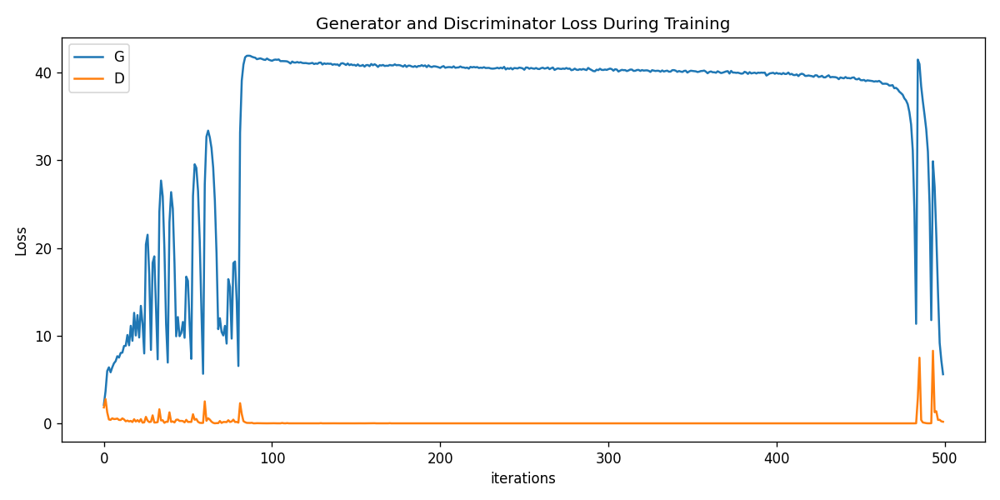

epoch_1.png


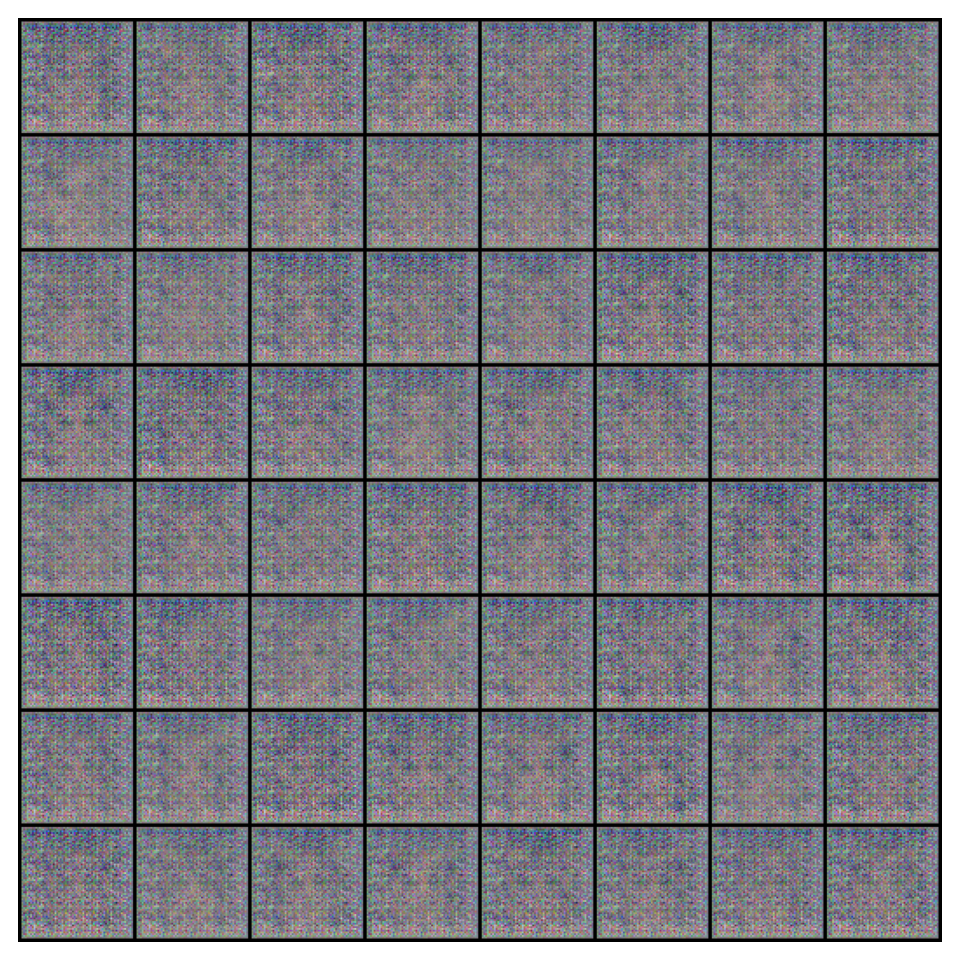

epoch_2.png


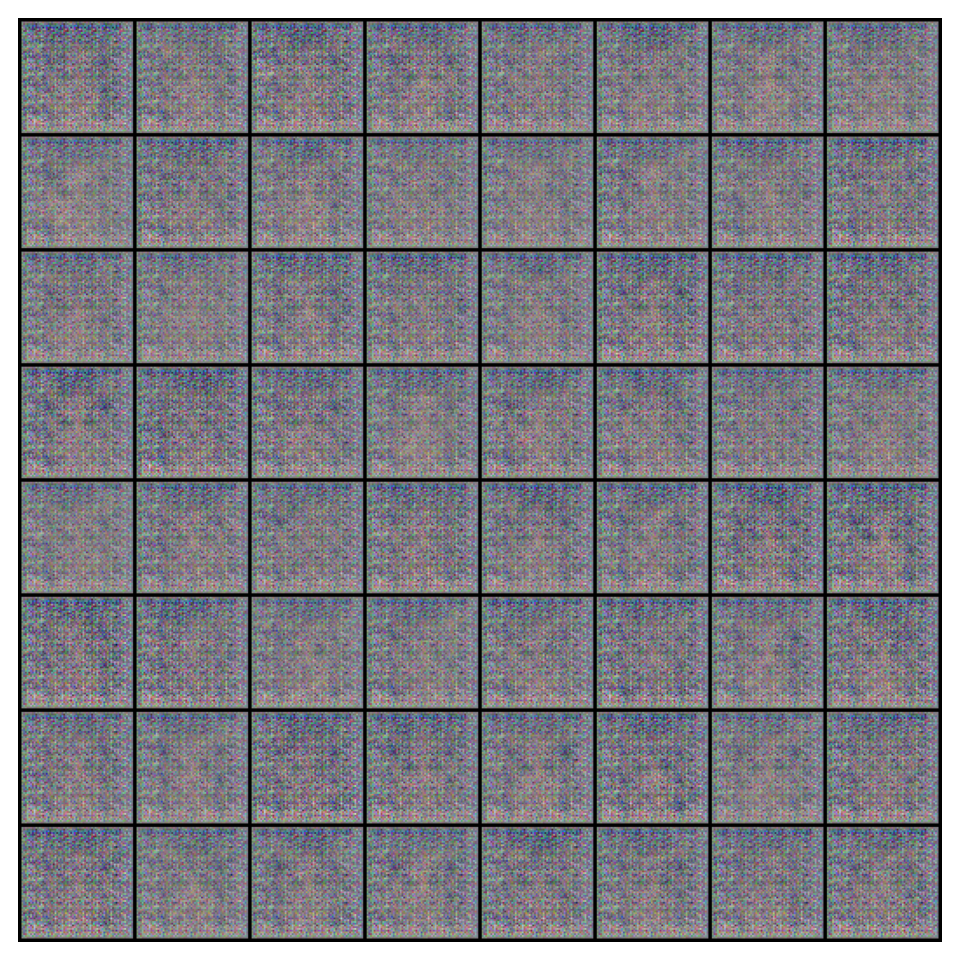

epoch_3.png


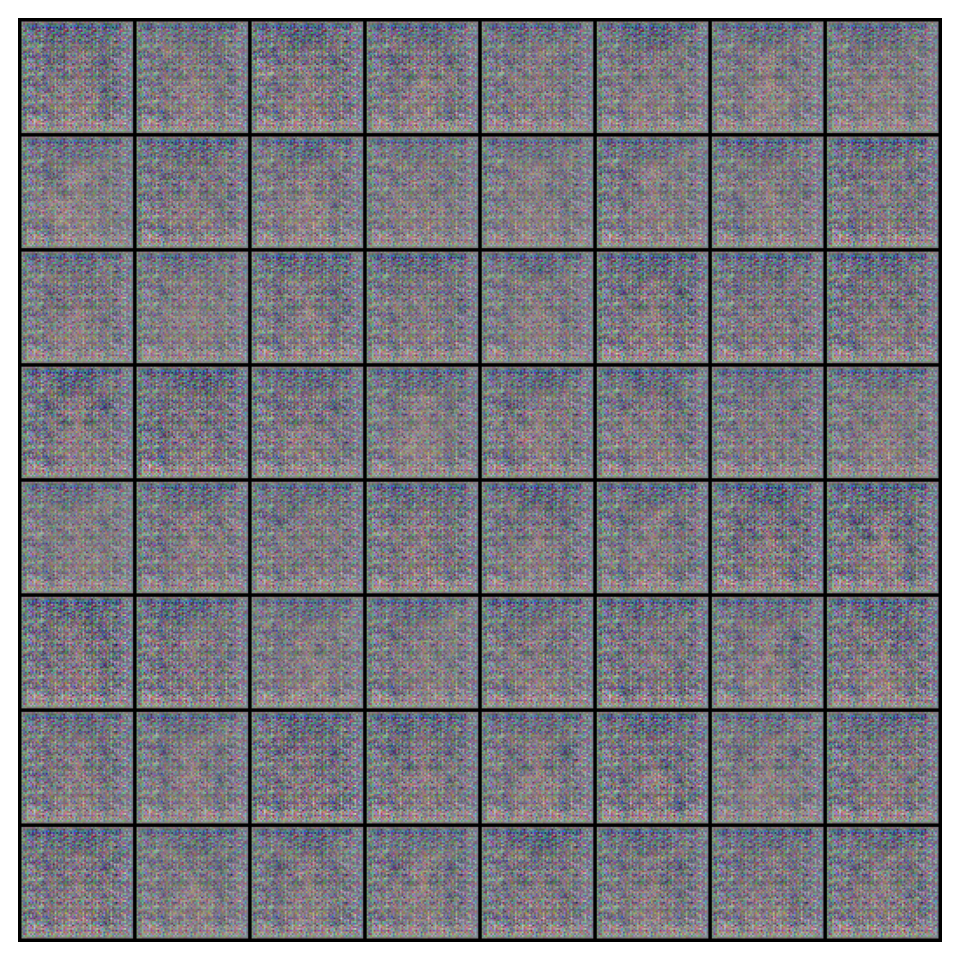

epoch_4.png


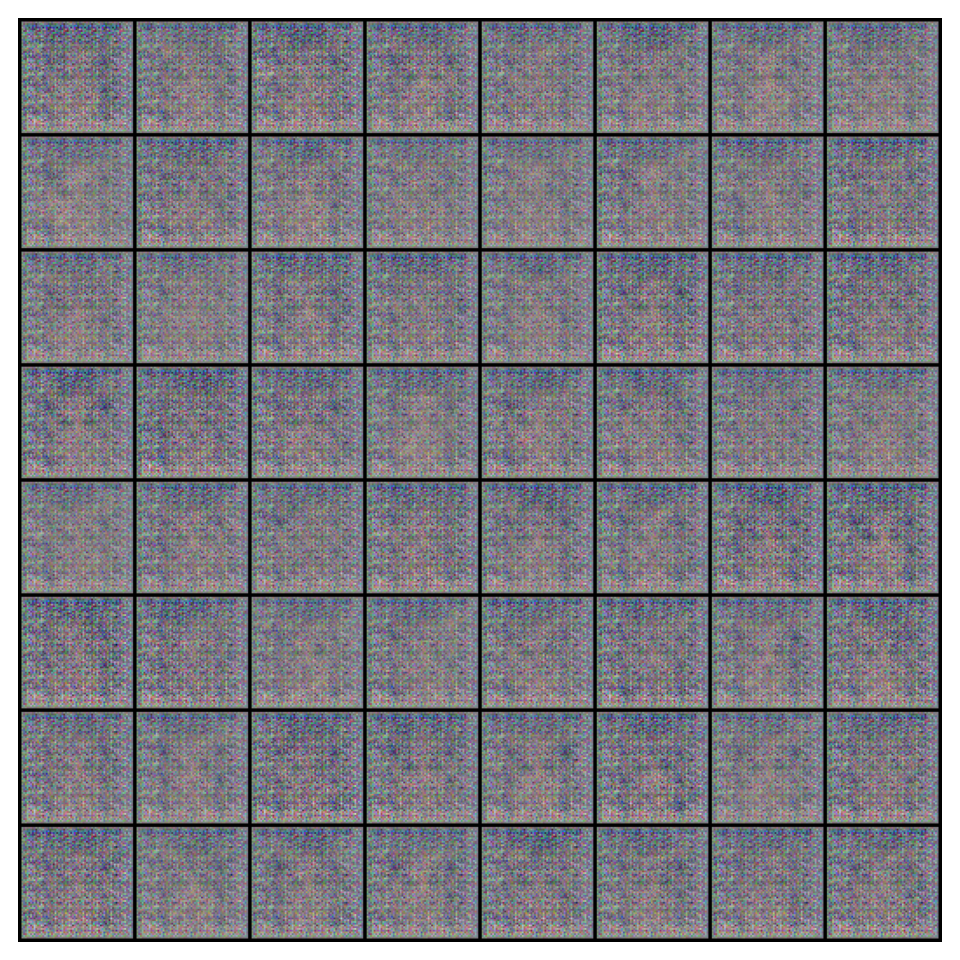

epoch_5.png


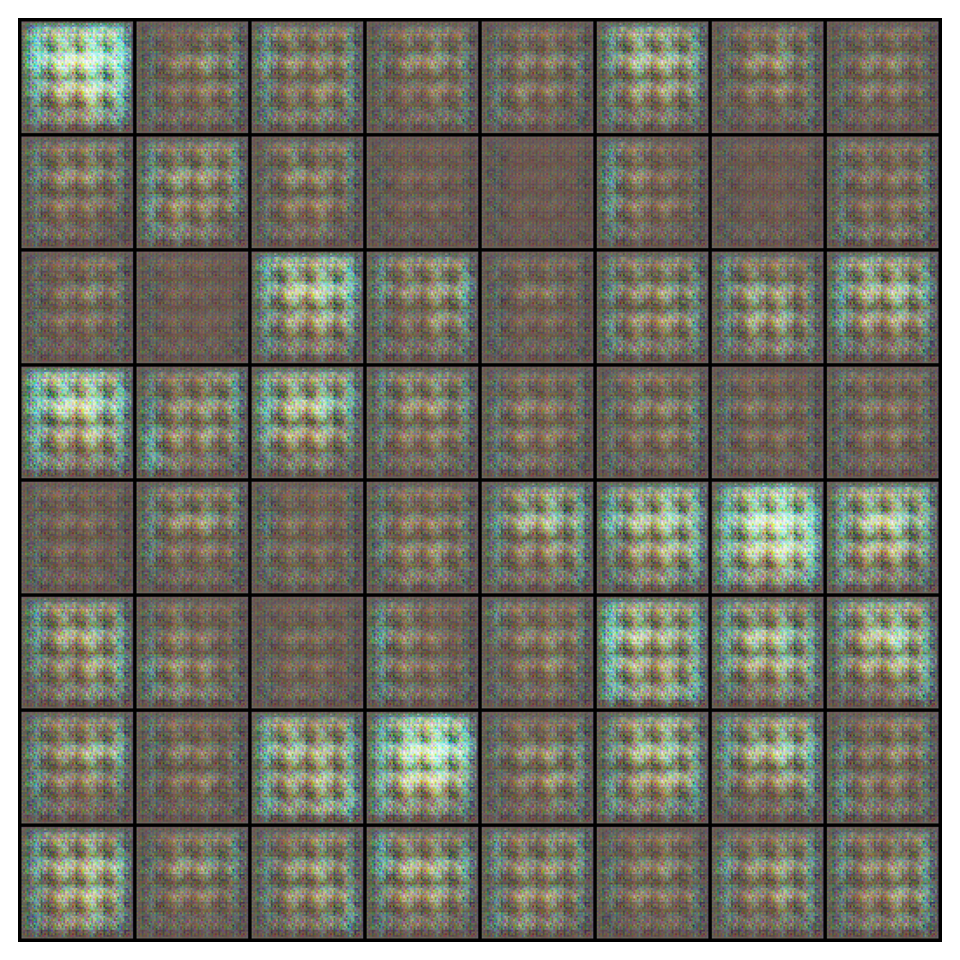

real_vs_fake.png


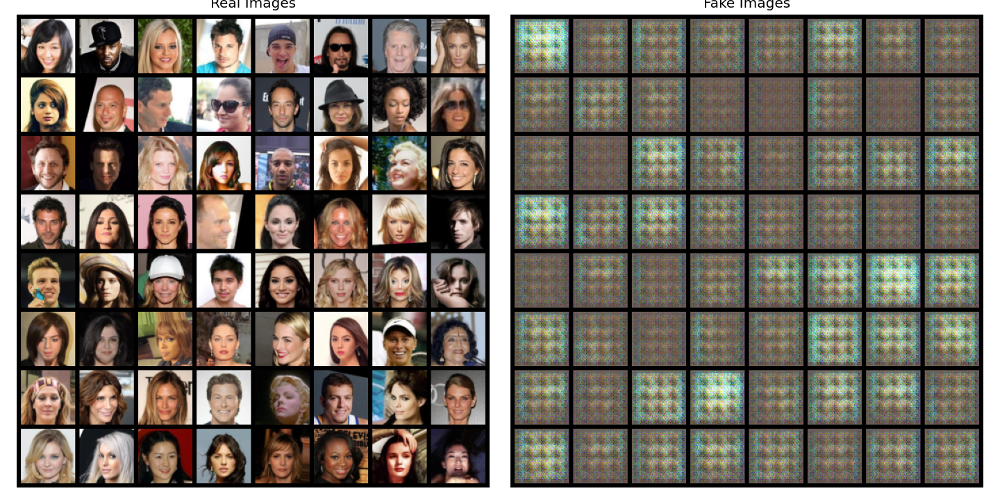

In [4]:
from IPython.display import Image, display
display(Image(r'runs/tutorial/loss_curve.png'))
for k in range(1, 6):
    display(Image(rf'runs/tutorial/epoch_{k}.png'))
display(Image(r'runs/tutorial/real_vs_fake.png'))


## Batch normalization

Batch norm is applied to a convolution's output before the nonlinearity. For each channel it subtracts the minibatch mean, divides by the minibatch standard deviation, then applies a learned scale and shift.

In the generator it is on every conv-transpose layer except the last. Those layers turn the noise vector into a spatial feature map. A discriminator step changes what the generator has to match, so the activations inside the generator would otherwise jump and the next layer would see a new input distribution. Batch norm holds each feature map to a common scale, which is what lets both networks train at the DCGAN learning rate of 0.0002. The last layer is left without it because that layer is a tanh whose job is to put pixels in the range -1 to 1. Normalizing that output would fight the image range.

In the discriminator, batch norm is only on the middle convolutions. The first layer has none, so the discriminator scores the image values themselves. The last convolution has none, so the sigmoid receives a raw score instead of a score that was forced back to zero mean. The middle layers keep the leaky ReLU features on a stable scale while the generator's outputs are moving. That matters because the discriminator's input distribution changes on every generator step. This is the DCGAN pattern: batch norm in both networks so the gradients still reach the early layers, with those two layers left out.

The two-layer discriminator in experiment 3 is different on purpose. The assigned diagram puts batch norm after the first convolution, and that run follows the diagram.

## Experiment 2. Discriminator updated five times as often

The discriminator is updated on every batch. The generator is updated only when the iteration count is a multiple of 5, so the discriminator takes five steps for each generator step. Each discriminator step uses a new real batch and a new noise sample. The generator loss is recorded only on the steps where the generator is updated. This is not tuned to beat the tutorial run.

In [5]:
print(open(r'runs/d5/log.txt', encoding='utf-8').read())

dataset images: 12800 (first 12800 of 202599 CelebA images)
dataloader workers: 4
batches per epoch: 100
Starting Training Loop...
[0/5][0/100]	Loss_D: 1.8134	Loss_G: 2.1164	D(x): 0.3093	D(G(z)): 0.3012 / 0.1568
[0/5][50/100]	Loss_D: 0.0274	Loss_G: 18.7424	D(x): 0.9818	D(G(z)): 0.0000 / 0.0000
epoch 1 done in 176.3s
[1/5][0/100]	Loss_D: 0.0044	Loss_G: 20.4710	D(x): 0.9959	D(G(z)): 0.0000 / 0.0000
[1/5][50/100]	Loss_D: 0.0012	Loss_G: 34.5344	D(x): 0.9988	D(G(z)): 0.0000 / 0.0000
epoch 2 done in 173.9s
[2/5][0/100]	Loss_D: 0.0001	Loss_G: 13.6928	D(x): 0.9999	D(G(z)): 0.0000 / 0.0000
[2/5][50/100]	Loss_D: 0.0005	Loss_G: 39.0544	D(x): 0.9995	D(G(z)): 0.0000 / 0.0000
epoch 3 done in 177.9s
[3/5][0/100]	Loss_D: 0.0000	Loss_G: 39.0681	D(x): 1.0000	D(G(z)): 0.0000 / 0.0000
[3/5][50/100]	Loss_D: 0.0001	Loss_G: 39.1564	D(x): 0.9999	D(G(z)): 0.0000 / 0.0000
epoch 4 done in 181.1s
[4/5][0/100]	Loss_D: 0.0000	Loss_G: 38.9207	D(x): 1.0000	D(G(z)): 0.0000 / 0.0000
[4/5][50/100]	Loss_D: 0.0001	Loss_G:

loss_curve.png


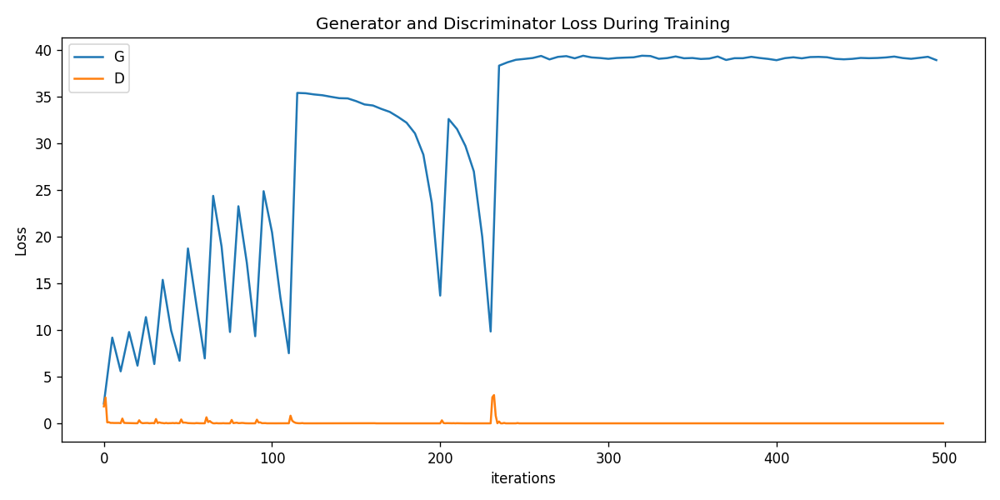

epoch_1.png


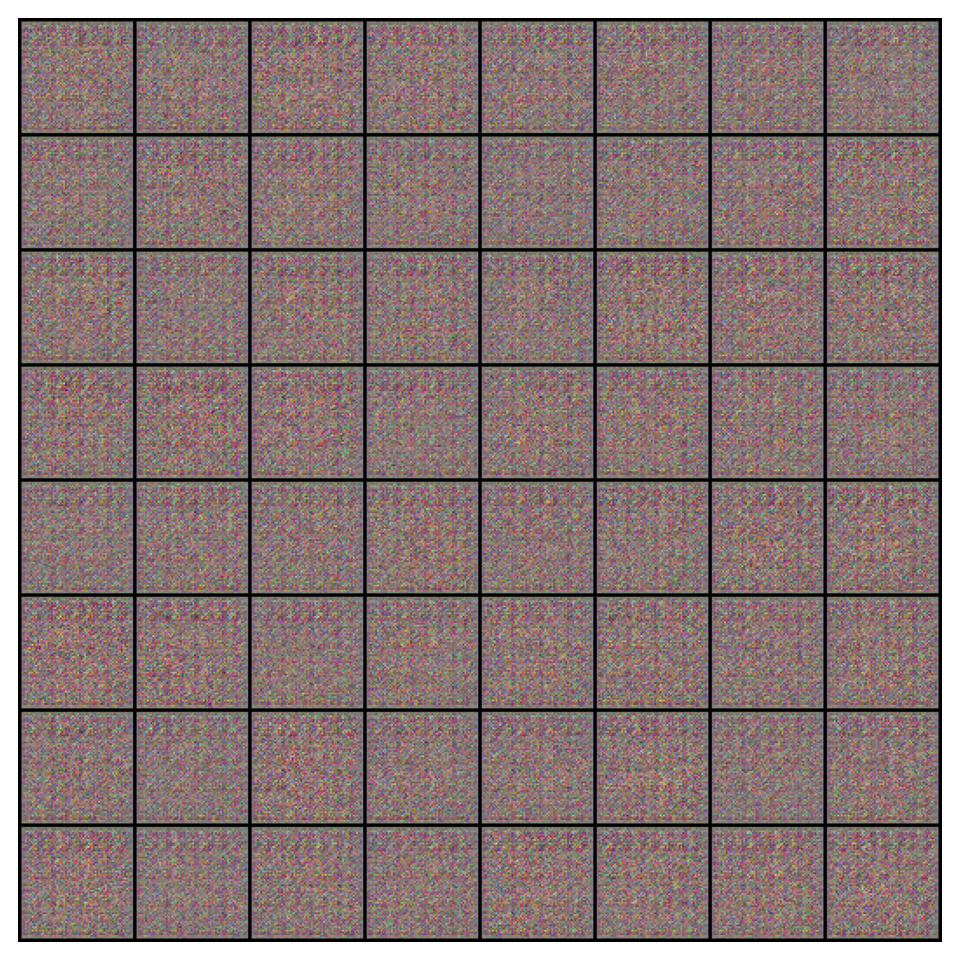

epoch_2.png


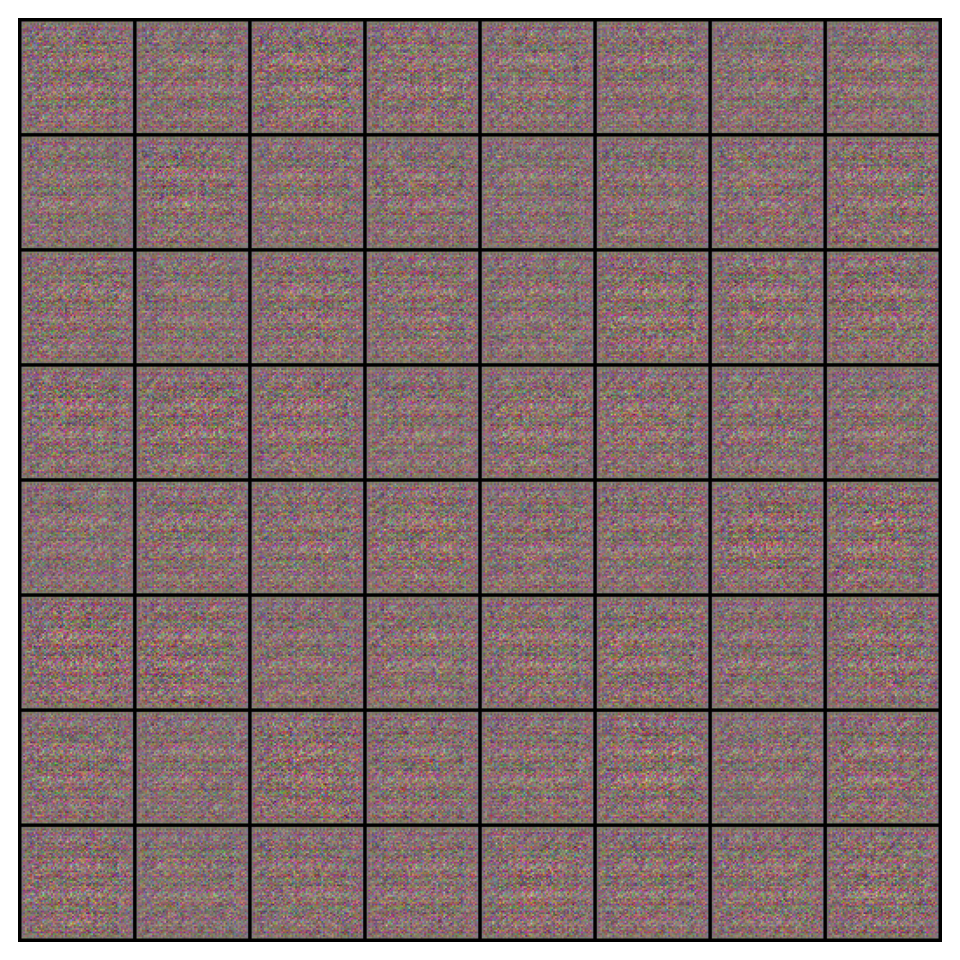

epoch_3.png


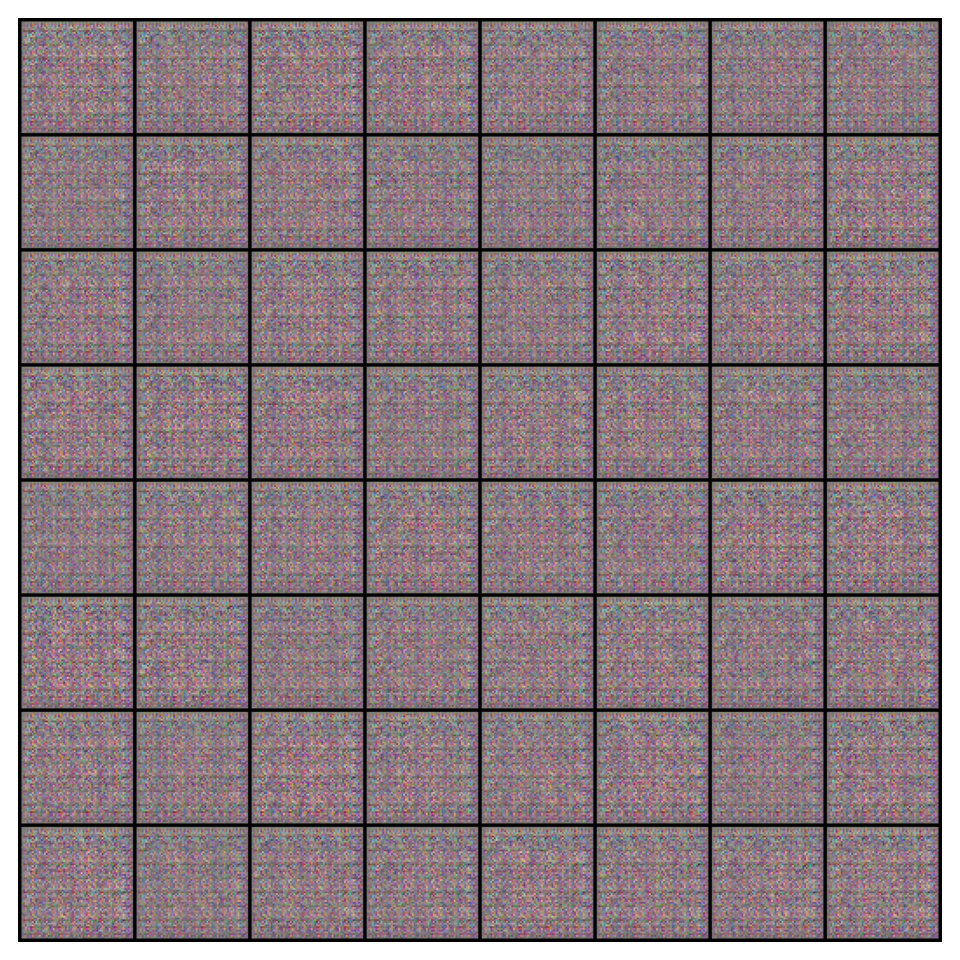

epoch_4.png


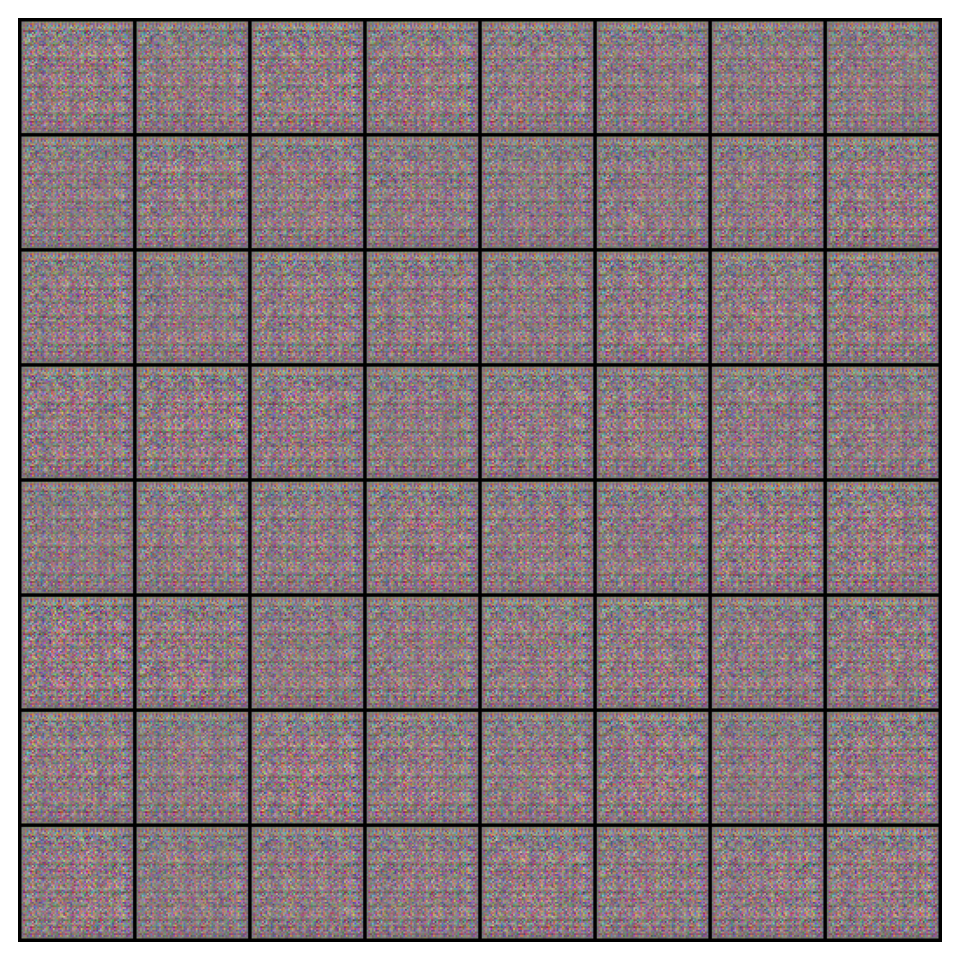

epoch_5.png


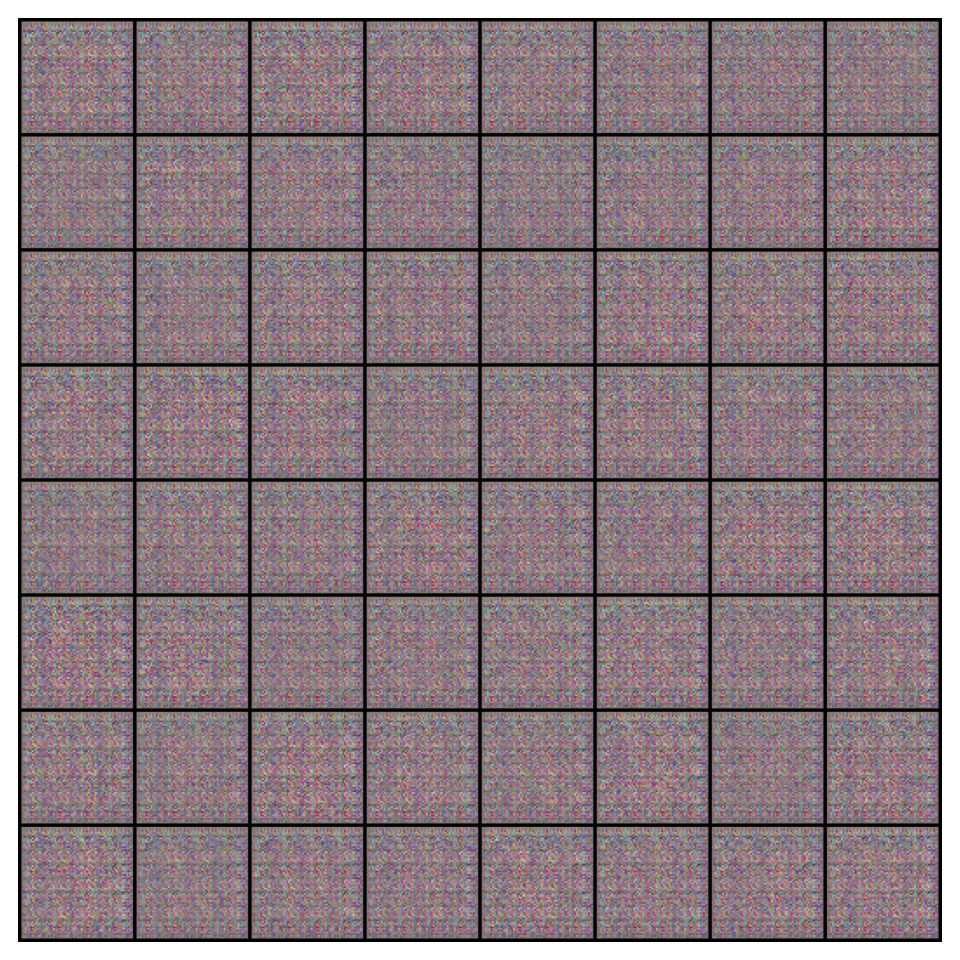

real_vs_fake.png


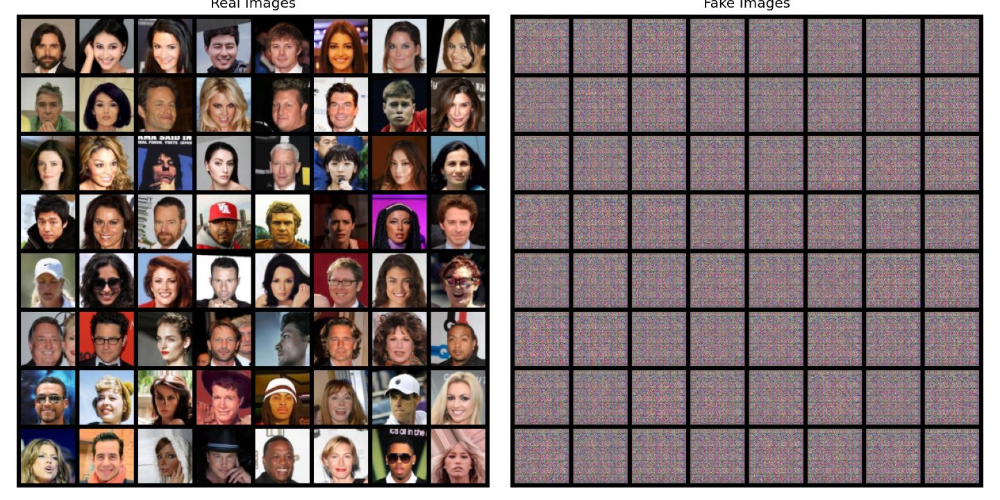

In [6]:
from IPython.display import Image, display
display(Image(r'runs/d5/loss_curve.png'))
for k in range(1, 6):
    display(Image(rf'runs/d5/epoch_{k}.png'))
display(Image(r'runs/d5/real_vs_fake.png'))


## Experiment 3. Two-convolution discriminator

The generator is unchanged. The discriminator is the two-layer network from the assignment: a stride-2 convolution from 3 channels to 64, batch norm, leaky ReLU, a stride-1 convolution down to 1 channel, adaptive average pooling to 1x1, and a sigmoid. Both networks start from new weights and train for 5 epochs with one discriminator step per generator step.

In [7]:
print(open(r'runs/simple/models.txt', encoding='utf-8').read())

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


In [8]:
print(open(r'runs/simple/log.txt', encoding='utf-8').read())

dataset images: 12800 (first 12800 of 202599 CelebA images)
dataloader workers: 4
batches per epoch: 100
Starting Training Loop...
[0/5][0/100]	Loss_D: 1.4062	Loss_G: 0.6395	D(x): 0.5338	D(G(z)): 0.5407 / 0.5275
[0/5][50/100]	Loss_D: 1.4150	Loss_G: 0.6362	D(x): 0.5195	D(G(z)): 0.5320 / 0.5293
epoch 1 done in 112.0s
[1/5][0/100]	Loss_D: 1.4166	Loss_G: 0.6244	D(x): 0.5240	D(G(z)): 0.5369 / 0.5356
[1/5][50/100]	Loss_D: 1.3937	Loss_G: 0.6378	D(x): 0.5277	D(G(z)): 0.5295 / 0.5285
epoch 2 done in 117.6s
[2/5][0/100]	Loss_D: 1.3795	Loss_G: 0.6620	D(x): 0.5219	D(G(z)): 0.5171 / 0.5158
[2/5][50/100]	Loss_D: 1.3628	Loss_G: 0.6833	D(x): 0.5200	D(G(z)): 0.5068 / 0.5050
epoch 3 done in 116.4s
[3/5][0/100]	Loss_D: 1.3484	Loss_G: 0.7021	D(x): 0.5203	D(G(z)): 0.4979 / 0.4955
[3/5][50/100]	Loss_D: 1.3299	Loss_G: 0.7280	D(x): 0.5203	D(G(z)): 0.4891 / 0.4829
epoch 4 done in 118.6s
[4/5][0/100]	Loss_D: 1.3059	Loss_G: 0.7528	D(x): 0.5244	D(G(z)): 0.4801 / 0.4710
[4/5][50/100]	Loss_D: 1.3122	Loss_G: 0.7461	

loss_curve.png


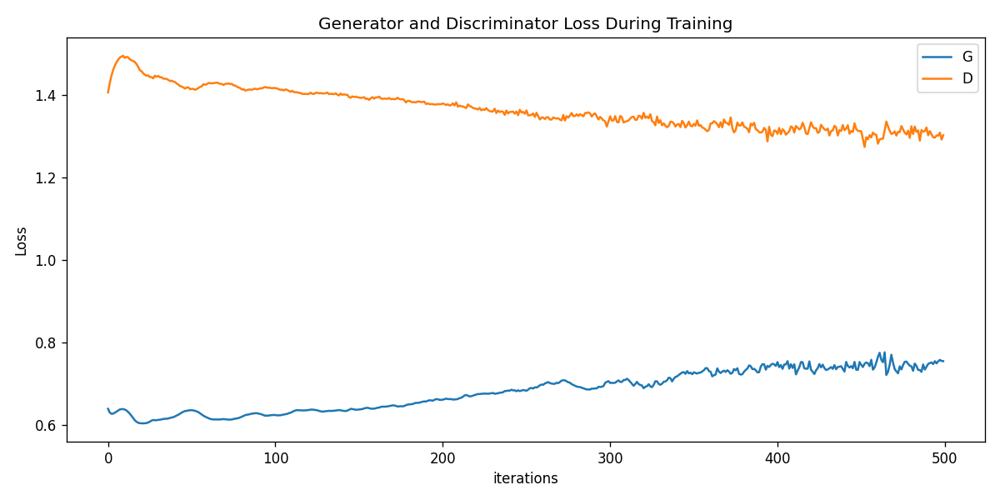

epoch_1.png


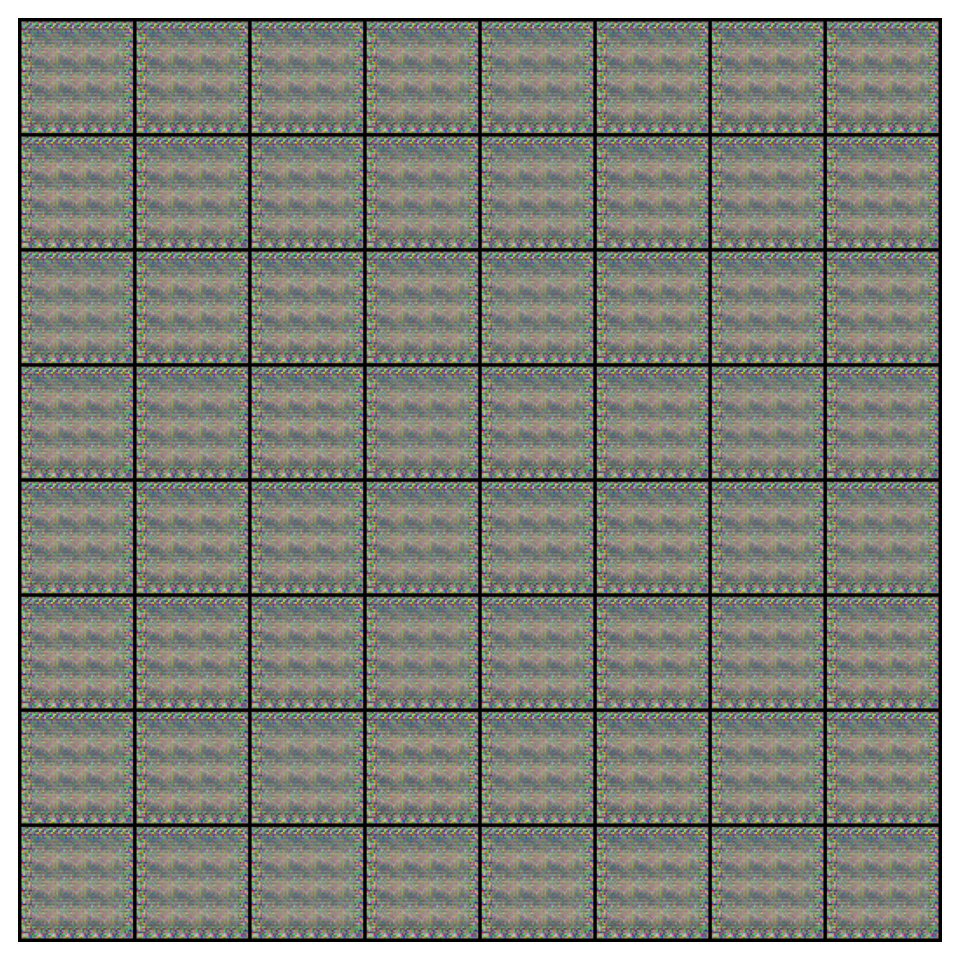

epoch_2.png


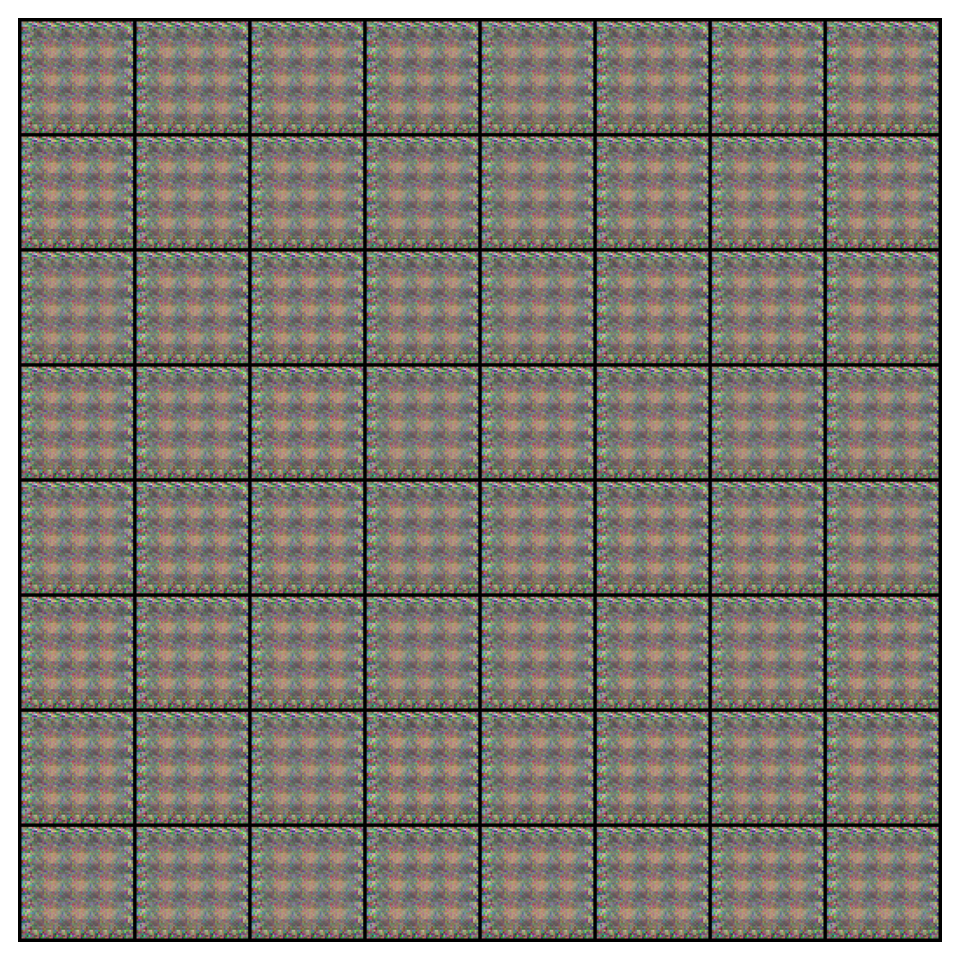

epoch_3.png


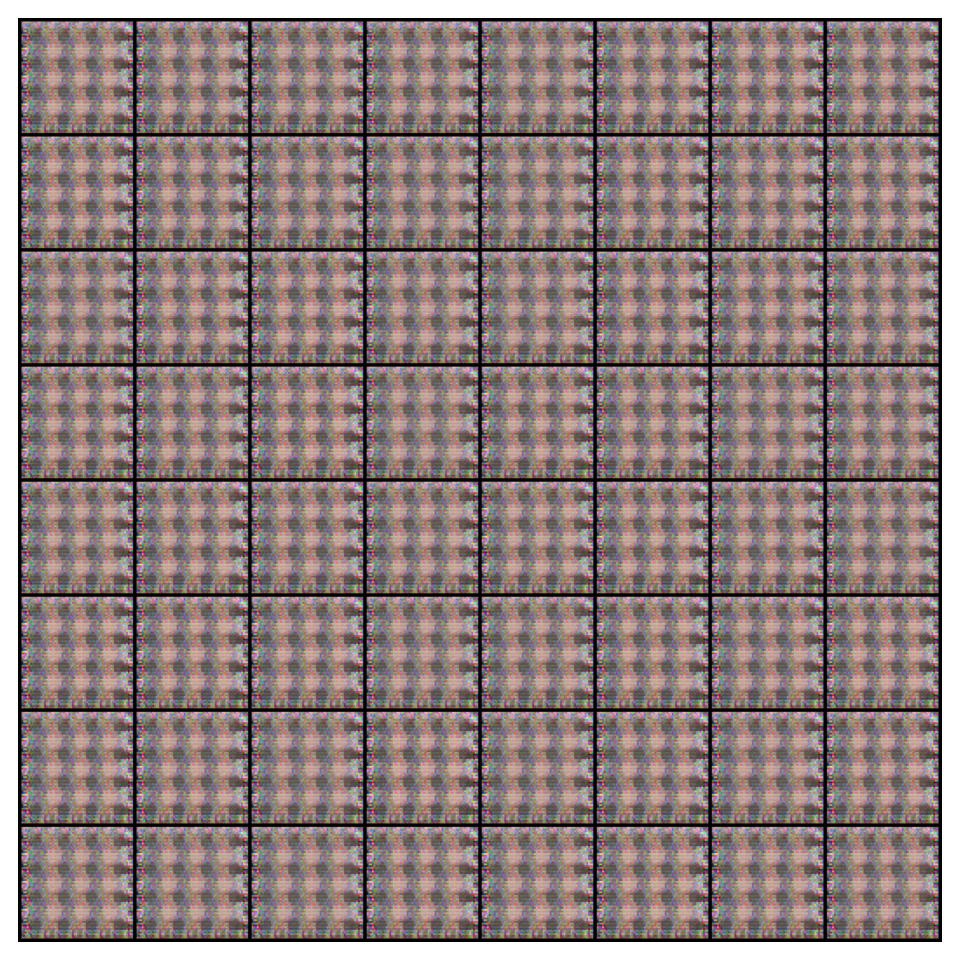

epoch_4.png


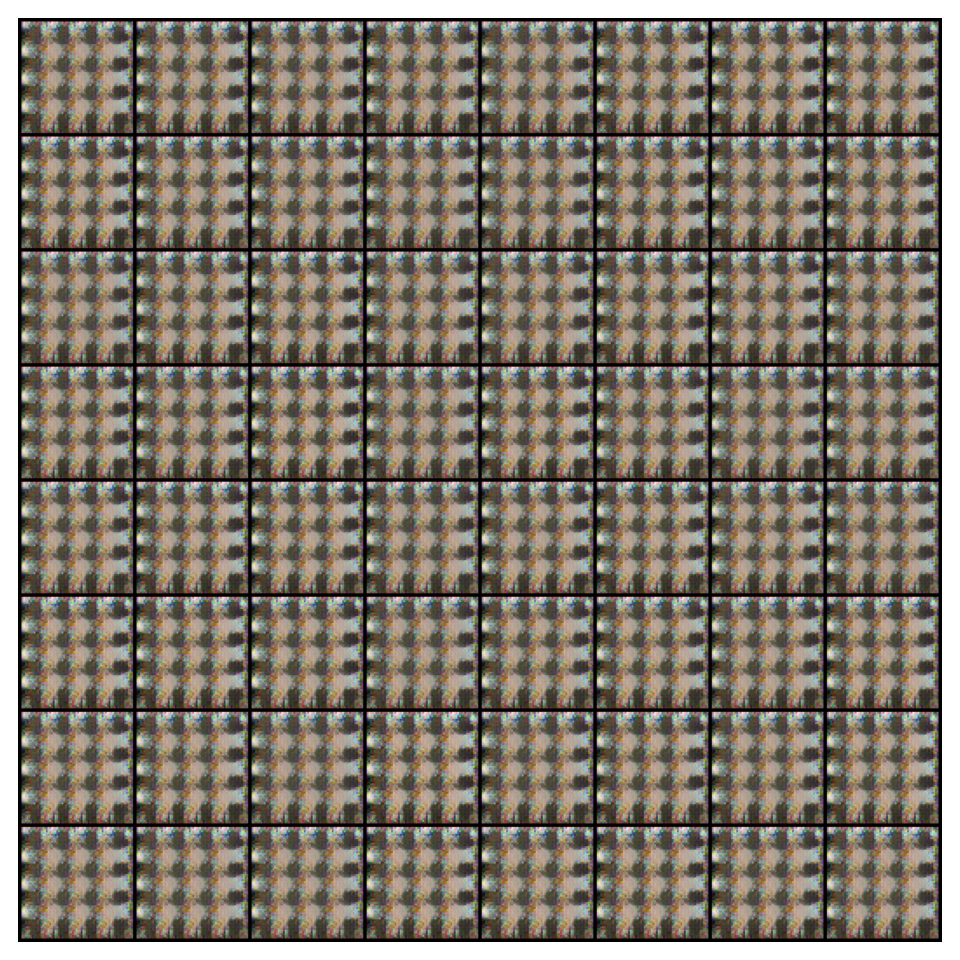

epoch_5.png


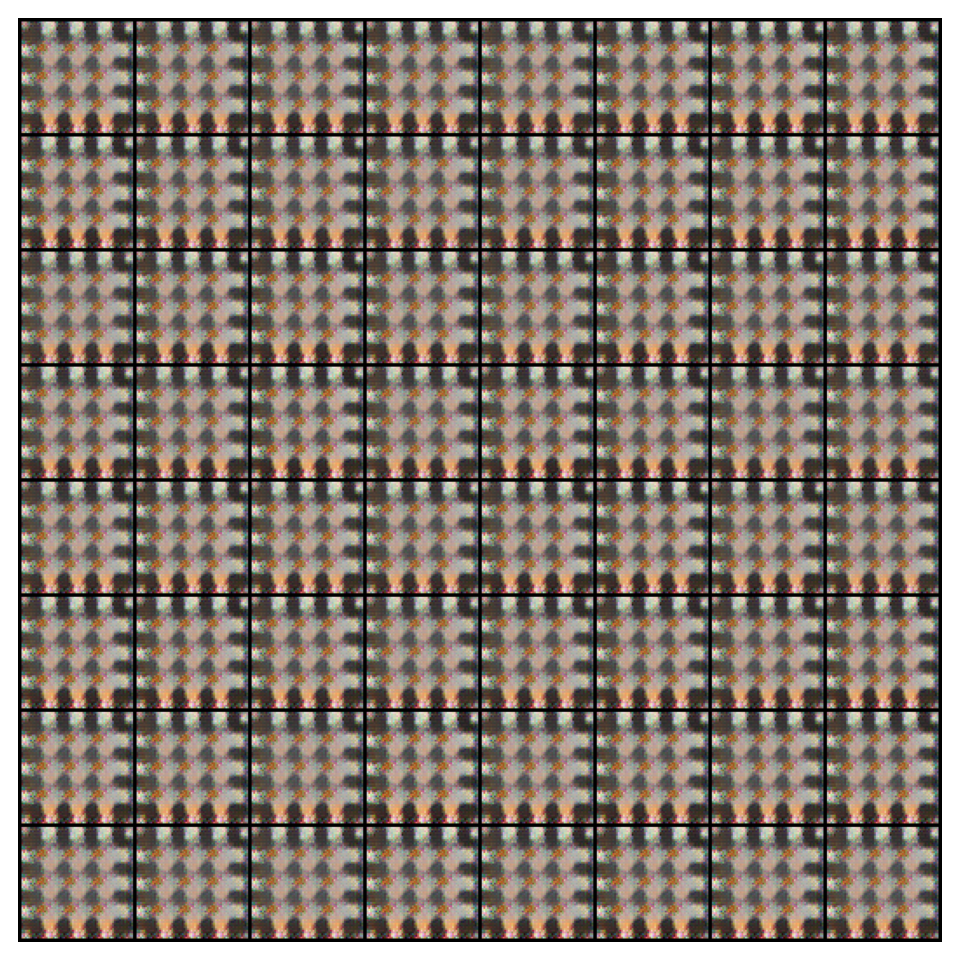

real_vs_fake.png


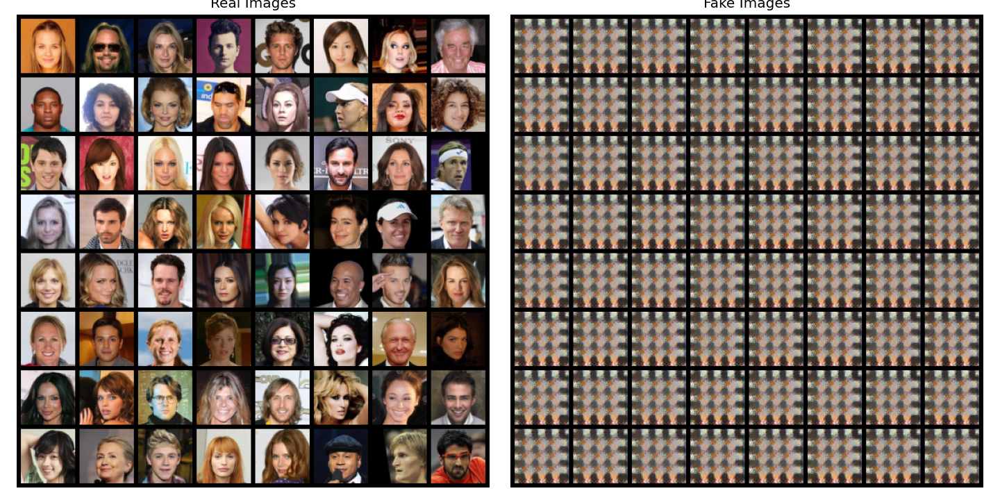

In [9]:
from IPython.display import Image, display
display(Image(r'runs/simple/loss_curve.png'))
for k in range(1, 6):
    display(Image(rf'runs/simple/epoch_{k}.png'))
display(Image(r'runs/simple/real_vs_fake.png'))
